# Praktikum 4
Klasifikasi Citra Wajah dengan SVM

Setelah memahami SVM pada data dummy, sekarang kita terapkan pada **data riil berdimensi tinggi**: citra wajah publik figur dari dataset **Labeled Faces in the Wild (LFW)**.

Setiap citra berukuran 62 × 47 piksel *grayscale*, sehingga satu citra menjadi vektor **2.914 fitur**. SVM terkenal baik untuk data berdimensi tinggi, tetapi kita juga perlu **reduksi dimensi** (PCA) agar komputasi tetap wajar.

**Alur:** unduh data → inspeksi citra → pipeline PCA + SVC → split → `GridSearchCV` untuk tuning `C` dan `gamma` → evaluasi dengan *classification report* dan *confusion matrix*.

> **Catatan lingkungan:** `fetch_lfw_people` mengunduh data (~200 MB) pada eksekusi pertama dan menyimpannya di `~/scikit_learn_data`. Bila muncul `CERTIFICATE_VERIFY_FAILED`, arahkan Python ke bundel CA, misalnya `export SSL_CERT_FILE=$(python -c "import certifi; print(certifi.where())")`.

### Langkah 0 - Unduh Dataset
`min_faces_per_person=60` menyaring agar hanya wajah dengan minimal 60 citra yang dipakai — dataset menjadi lebih seimbang dan cukup kecil untuk dilatih.

In [1]:
from sklearn.datasets import fetch_lfw_people

faces = fetch_lfw_people(min_faces_per_person=60)
print(faces.target_names)
print(len(faces.target_names))
print(faces.images.shape)
print(faces.data.shape)

['Ariel Sharon' 'Colin Powell' 'Donald Rumsfeld' 'George W Bush'
 'Gerhard Schroeder' 'Hugo Chavez' 'Junichiro Koizumi' 'Tony Blair']
8
(1348, 62, 47)
(1348, 2914)


Didapatkan **8 kelas** dan **1.348 citra** berukuran 62 × 47.

### Langkah 1 - Inspeksi Citra Wajah

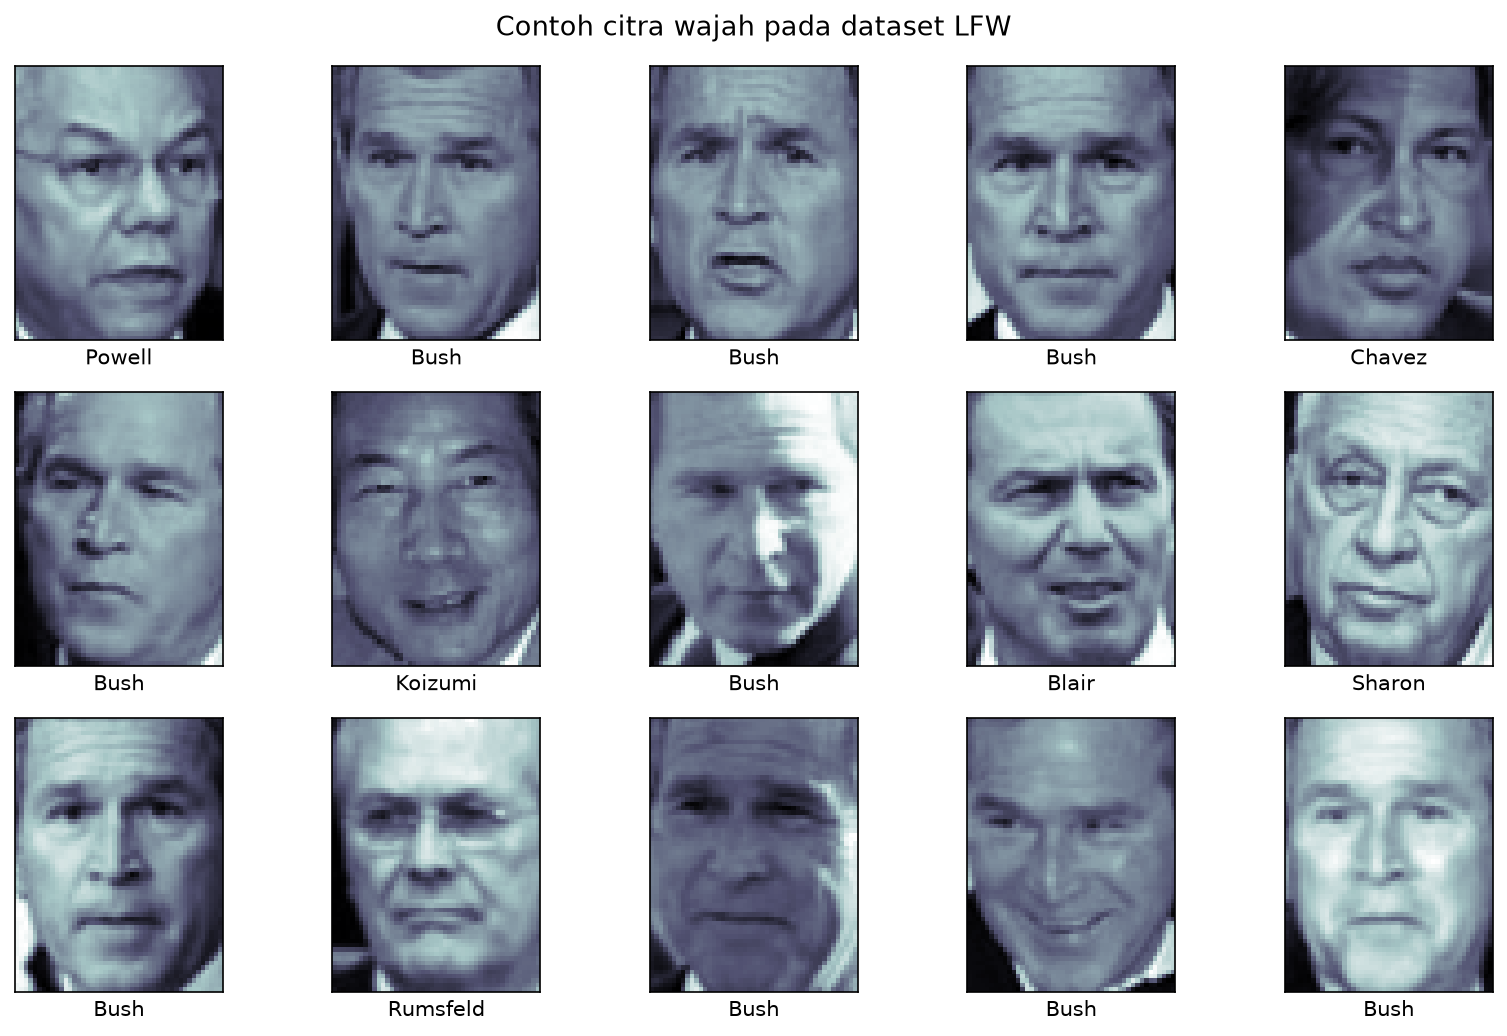

In [2]:
import pandas as pd
from matplotlib import pyplot as plt

fig, ax = plt.subplots(3, 5, figsize=(11, 7))
for i, axi in enumerate(ax.flat):
    axi.imshow(faces.images[i], cmap='bone')
    axi.set(xticks=[], yticks=[],
            xlabel=faces.target_names[faces.target[i]].split()[-1])

plt.suptitle('Contoh citra wajah pada dataset LFW', size=13)
plt.tight_layout()
plt.show()

### Langkah 2 - Pra Pengolahan Data
**Principal Component Analysis (PCA)** memproyeksikan 2.914 fitur piksel ke **150 komponen utama** yang paling banyak menyimpan variasi data. Selain mempercepat SVM, PCA juga menekan noise pada piksel.

`whiten=True` menormalkan variansi tiap komponen sehingga kernel RBF menerima fitur dengan skala setara. `class_weight='balanced'` membuat SVM memberi bobot lebih pada kelas yang jumlahnya sedikit.

In [3]:
from sklearn.svm import SVC
from sklearn.decomposition import PCA as RandomizedPCA
from sklearn.pipeline import make_pipeline

pca = RandomizedPCA(n_components=150, whiten=True, random_state=42)
svc = SVC(kernel='rbf', class_weight='balanced')

# Pipeline menjalankan PCA lalu SVC dalam satu objek
model = make_pipeline(pca, svc)

model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('pca', ...), ('svc', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",150
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",True
,"random_state random_state: int, RandomState instance or None, default=NoneUsed when the 'arpack' or 'randomized' solvers are used. Pass an intfor reproducible results across multiple function calls.See :term:`Glossary <random_state>`... versionadded:: 0.18.0",42
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the numbe

### Langkah 3 - Split Data

In [4]:
from sklearn.model_selection import train_test_split

Xtrain, Xtest, ytrain, ytest = train_test_split(faces.data, faces.target,
                                                random_state=42)

print('Data latih:', Xtrain.shape, '| Data uji:', Xtest.shape)

Data latih: (1011, 2914) | Data uji: (337, 2914)


### Langkah 4 - Pembuatan Model + Tunning
`GridSearchCV` mencoba setiap kombinasi hyperparameter satu per satu dengan **cross-validation**, lalu memilih kombinasi dengan skor terbaik. Cara ini mudah, tetapi boros waktu dan komputasi.

Karena nama langkah pada pipeline adalah `pca` dan `svc`, nama parameternya ditulis `svc__C` dan `svc__gamma`.

In [5]:
from sklearn.model_selection import GridSearchCV

param_grid = {'svc__C': [1, 5, 10, 50],
              'svc__gamma': [0.0001, 0.0005, 0.001, 0.005]}
grid = GridSearchCV(model, param_grid, n_jobs=-1)

%time grid.fit(Xtrain, ytrain)
print(grid.best_params_)
print(grid.best_score_)

CPU times: user 330 ms, sys: 115 ms, total: 444 ms
Wall time: 10.7 s
{'svc__C': 5, 'svc__gamma': 0.001}
0.828893332683022


> **Penyesuaian:** ditambahkan `n_jobs=-1` agar seluruh core CPU dipakai, karena 16 kombinasi × 5 fold cukup berat bila berjalan serial. Parameter grid dan `random_state` tetap seperti modul, sehingga hasil terbaiknya sama.

In [6]:
model = grid.best_estimator_
yfit = model.predict(Xtest)

print('Akurasi data uji:', (yfit == ytest).mean())

Akurasi data uji: 0.8486646884272997


### Langkah 5 - Cek Hasil Prediksi
Label di bawah setiap citra adalah hasil prediksi; label berwarna **merah** berarti prediksi salah.

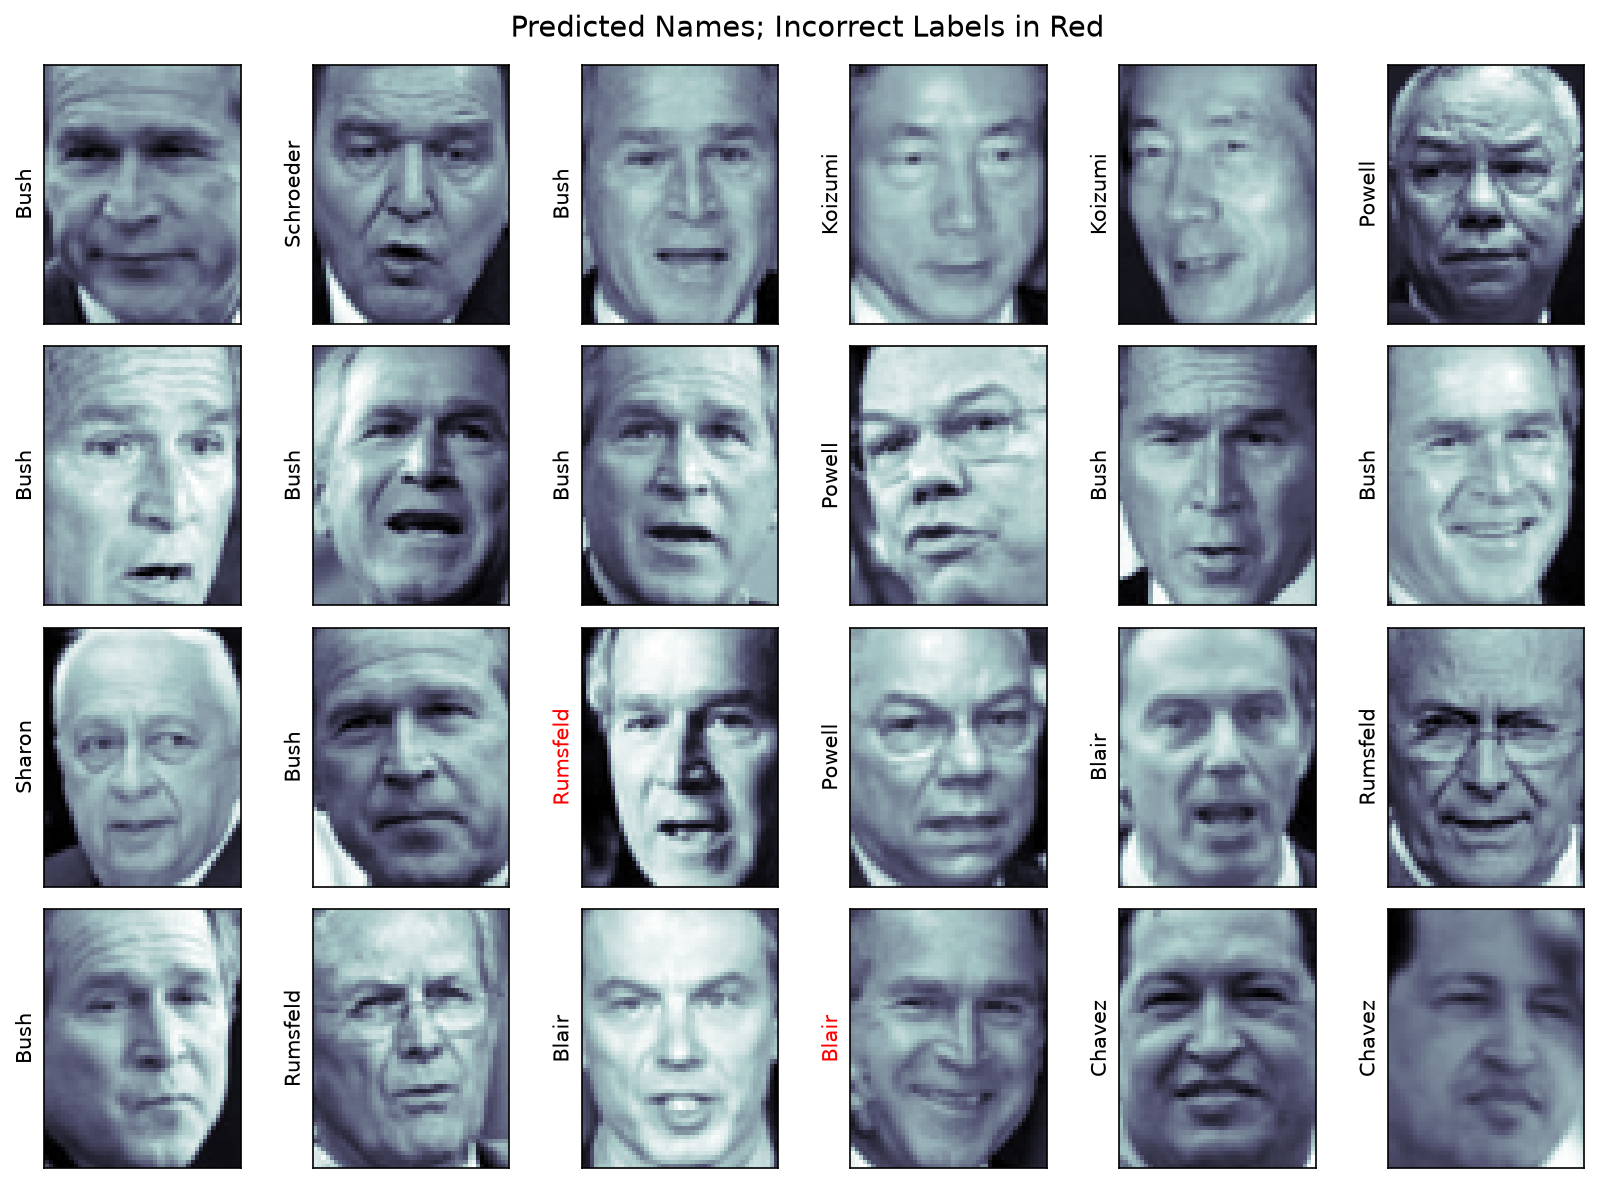

In [7]:
fig, ax = plt.subplots(4, 6, figsize=(11, 8))
for i, axi in enumerate(ax.flat):
    axi.imshow(Xtest[i].reshape(62, 47), cmap='bone')
    axi.set(xticks=[], yticks=[])
    axi.set_ylabel(faces.target_names[yfit[i]].split()[-1],
                   color='black' if yfit[i] == ytest[i] else 'red')
fig.suptitle('Predicted Names; Incorrect Labels in Red', size=14)
plt.tight_layout()
plt.show()

### Langkah 6 - Cek Performansi
`classification_report` memberi precision, recall, dan f1-score **per kelas**, sedangkan confusion matrix menunjukkan kelas mana yang paling sering tertukar.

In [8]:
from sklearn.metrics import classification_report

print(classification_report(ytest, yfit, target_names=faces.target_names))

                   precision    recall  f1-score   support

     Ariel Sharon       0.65      0.87      0.74        15
     Colin Powell       0.83      0.88      0.86        68
  Donald Rumsfeld       0.70      0.84      0.76        31
    George W Bush       0.97      0.80      0.88       126
Gerhard Schroeder       0.76      0.83      0.79        23
      Hugo Chavez       0.93      0.70      0.80        20
Junichiro Koizumi       0.86      1.00      0.92        12
       Tony Blair       0.82      0.98      0.89        42

         accuracy                           0.85       337
        macro avg       0.82      0.86      0.83       337
     weighted avg       0.86      0.85      0.85       337



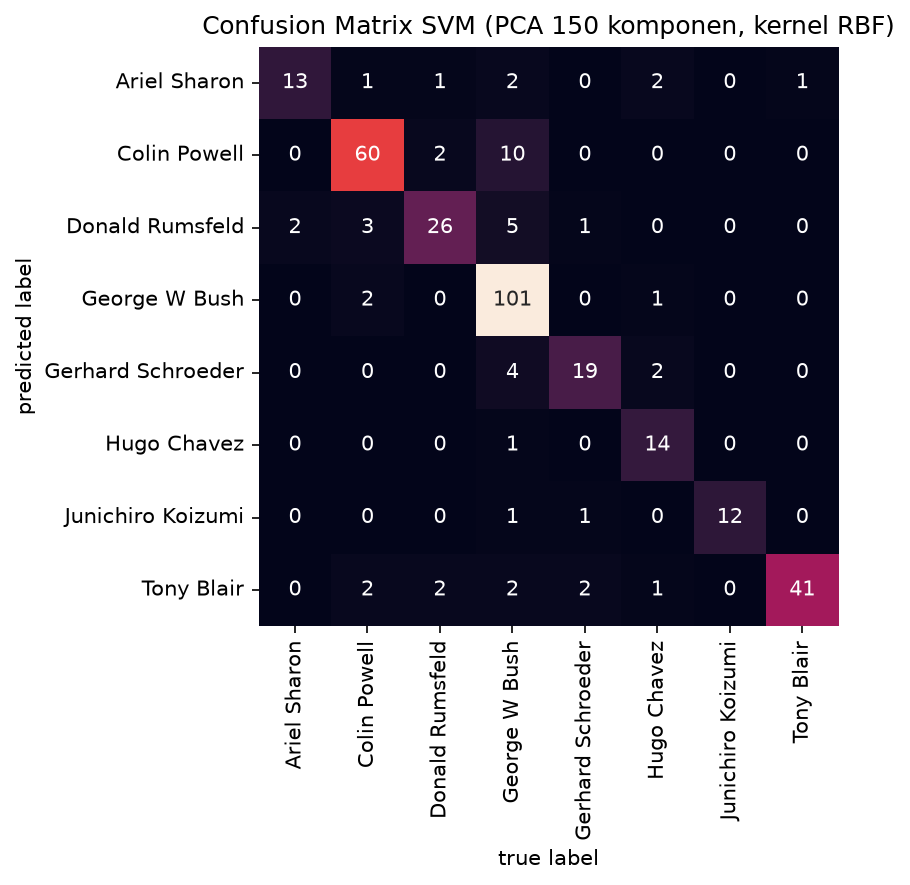

In [9]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

mat = confusion_matrix(ytest, yfit)
plt.figure(figsize=(8, 6))
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
            xticklabels=faces.target_names,
            yticklabels=faces.target_names)
plt.xlabel('true label')
plt.ylabel('predicted label')
plt.title('Confusion Matrix SVM (PCA 150 komponen, kernel RBF)')
plt.tight_layout()
plt.show()

In [10]:
# Ringkasan hasil pencarian hyperparameter
hasil_grid = pd.DataFrame(grid.cv_results_)[['param_svc__C', 'param_svc__gamma',
                                             'mean_test_score', 'std_test_score']]
hasil_grid['param_svc__gamma'] = hasil_grid['param_svc__gamma'].astype(float)
hasil_grid = hasil_grid.sort_values('mean_test_score', ascending=False)
hasil_grid.head(6).round(4)

,param_svc__C,param_svc__gamma,mean_test_score,std_test_score
6,5,0.0010,0.8289,0.0100
5,5,0.0005,0.8260,0.0261
3,1,0.0050,0.8220,0.0103
2,1,0.0010,0.8210,0.0237
10,10,0.0010,0.8180,0.0202
9,10,0.0005,0.8170,0.0123


### Kesimpulan

* SVM dengan **kernel RBF** sanggup mengklasifikasikan 8 kelas wajah hanya dari piksel mentah, dengan akurasi uji sekitar **0,85** — hasil yang kuat mengingat citra tidak diselaraskan dan pencahayaan berbeda-beda.
* **PCA 150 komponen** mempercepat pelatihan secara drastis dibanding 2.914 fitur piksel, sekaligus menekan noise; `whiten=True` membuat skala tiap komponen setara sehingga `gamma` lebih mudah disetel.
* `GridSearchCV` memilih `C` dan `gamma` terbaik secara empiris. Kombinasi inilah yang menentukan trade-off antara margin lebar dan kesalahan klasifikasi; menebak nilainya hampir mustahil tanpa pencarian.
* Kesalahan prediksi paling banyak terjadi pada figur yang wajahnya mirip atau jumlah citranya sedikit — terlihat pada confusion matrix dan label merah di Langkah 5.
* Keterbatasan: `GridSearchCV` mahal secara komputasi, dan SVM kernel non-linear sulit diinterpretasikan. Untuk data yang jauh lebih besar, SVM satu-per-satu menjadi kurang praktis.